# Análisis de Ciudades de Chile: Comparativo, Clusterización y Reducción Dimensional

1. Carga y exploración de datos
2. Preprocesamiento: imputación, outliers, normalización y codificación
3. Estudio comparativo entre ciudades (regresión lineal múltiple)
4. Cálculo de k óptimo (método del codo y Silhouette Score)
5. Clusterización y reducción dimensional (PCA, t-SNE, K-Means, Jerárquico, DBSCAN)
6. Visualización de clusters en espacio reducido (PCA y t-SNE)
7. Visualización y análisis de resultados
8. Ejemplo de aplicación: segmentación para políticas públicas
9. Recomendaciones prácticas y conclusiones

## 1. Carga y exploración de datos
Simulación dataset de ciudades de Chile con densidad poblacional, tasa de migración e índice de delincuencia.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
ciudades = ['Santiago','Valparaíso','Concepción','La Serena','Antofagasta','Temuco','Iquique','Rancagua','Talca','Arica','Puerto Montt','Copiapó','Punta Arenas','Chillán','Calama','Osorno','Valdivia','Quillota','Coronel','San Antonio']
n = len(ciudades)
df = pd.DataFrame({
    'Ciudad': ciudades,
    'Densidad_Poblacional': np.random.uniform(1000, 9000, n),
    'Tasa_Migracion': np.random.uniform(-5, 15, n),
    'Indice_Delincuencia': np.random.uniform(10, 80, n),
    'Ingreso_Promedio': np.random.normal(700000, 150000, n),
    'Tasa_Desempleo': np.random.uniform(3, 12, n)
})
print('Primeras filas:')
display(df.head())
print('Resumen estadístico:')
display(df.describe())

Primeras filas:


,Ciudad,Densidad_Poblacional,Tasa_Migracion,Indice_Delincuencia,Ingreso_Promedio,Tasa_Desempleo
0,Santiago,3996.320951,7.237058,18.542676,478221.701445,9.566456
1,Valparaíso,8605.714451,-2.210123,44.662384,592023.368741,8.738017
2,Concepción,6855.951534,0.842893,12.407196,630904.184356,10.984915
3,La Serena,5789.267874,2.327237,73.652428,858568.333933,7.249934
4,Antofagasta,2248.149124,4.121400,28.114599,751542.743435,4.076348


Resumen estadístico:


,Densidad_Poblacional,Tasa_Migracion,Indice_Delincuencia,Ingreso_Promedio,Tasa_Desempleo
count,20.000000,20.000000,20.000000,20.000000,20.000000
mean,4661.618307,4.096579,44.297974,670043.011425,7.444859
std,2461.494939,5.823581,23.155582,129943.888866,2.480626
min,1164.675954,-4.070992,12.407196,435543.976696,3.228772
25%,2464.076994,-1.152273,23.524053,587546.869435,5.682810
50%,4225.940550,3.962225,45.533573,647927.900780,7.640866
75%,6712.423350,7.598959,66.353952,761594.918408,9.456016
max,8759.278817,14.312641,77.870924,858568.333933,11.168098


## 2. Preprocesamiento: Imputación, outliers, normalización y escalamiento

In [2]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Imputación de valores faltantes en variables numéricas
num_cols = df.select_dtypes(include=[np.number]).columns
imputer = SimpleImputer(strategy='median')
df_num = pd.DataFrame(imputer.fit_transform(df[num_cols]), columns=num_cols)

# Codificación One-Hot de la columna 'Ciudad'
encoder = OneHotEncoder(sparse_output=False)
ciudad_encoded = encoder.fit_transform(df[['Ciudad']])
ciudad_df = pd.DataFrame(ciudad_encoded, columns=encoder.get_feature_names_out(['Ciudad']))

# Unir variables numéricas y categóricas codificadas
df_imputed = pd.concat([df_num, ciudad_df], axis=1)

# Calcular Q1, Q3 e IQR solo en columnas numéricas originales
Q1 = df_num.quantile(0.25)
Q3 = df_num.quantile(0.75)
IQR = Q3 - Q1
mask = ~((df_num < (Q1 - 1.5 * IQR)) | (df_num > (Q3 + 1.5 * IQR))).any(axis=1)
df_clean = df_imputed[mask].reset_index(drop=True)
print(f'Se eliminaron {len(df_imputed) - len(df_clean)} filas por outliers.')

# Agregar la columna 'Ciudad' a df_clean para mantener los nombres originales
df_clean['Ciudad'] = df.loc[mask, 'Ciudad'].reset_index(drop=True)

# Escalar solo las columnas numéricas y codificadas (excluyendo 'Ciudad')
cols_to_scale = df_clean.columns.drop('Ciudad')
scaler = StandardScaler()
X = scaler.fit_transform(df_clean[cols_to_scale])

Se eliminaron 0 filas por outliers.


## 3. Estudio comparativo: Regresión lineal múltiple entre ciudades
Se realiza una regresión lineal múltiple para predecir el ingreso promedio de cada ciudad en función de la densidad poblacional, tasa de migración, índice de delincuencia y tasa de desempleo. Esto permite comparar el impacto relativo de cada variable sobre el ingreso y analizar diferencias entre ciudades.

In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# Seleccionar variables predictoras y objetivo
X_reg = df[['Densidad_Poblacional','Tasa_Migracion','Indice_Delincuencia','Tasa_Desempleo']]
y_reg = df['Ingreso_Promedio']

# Ajustar modelo de regresión lineal múltiple
reg = LinearRegression()
reg.fit(X_reg, y_reg)
y_pred = reg.predict(X_reg)

# Mostrar coeficientes
coef_df = pd.DataFrame({'Variable': X_reg.columns, 'Coeficiente': reg.coef_})
print('Coeficientes de la regresión:')
display(coef_df)

# Métricas de ajuste
print(f'R2: {r2_score(y_reg, y_pred):.3f}')
rmse = np.sqrt(mean_squared_error(y_reg, y_pred))
print(f'RMSE: {rmse:.2f}')

# Comparar predicción vs real por ciudad
resultados = pd.DataFrame({'Ciudad': df['Ciudad'], 'Ingreso_Real': y_reg, 'Ingreso_Predicho': y_pred})
display(resultados)

Coeficientes de la regresión:


,Variable,Coeficiente
0,Densidad_Poblacional,-15.660573
1,Tasa_Migracion,-9675.919246
2,Indice_Delincuencia,2830.918673
3,Tasa_Desempleo,-506.431197


R2: 0.272
RMSE: 108099.02


,Ciudad,Ingreso_Real,Ingreso_Predicho
0,Santiago,478221.701445,576089.336573
1,Valparaíso,592023.368741,669676.065800
2,Concepción,630904.184356,575087.910521
3,La Serena,858568.333933,752702.176467
4,Antofagasta,751542.743435,663491.261040
5,Temuco,435543.976696,677107.751039
6,Iquique,748612.595409,732944.971468
7,Rancagua,642237.657938,613028.408715
8,Talca,598461.699954,635430.992198
9,Arica,791751.443326,657241.366394


## 4. Cálculo de k óptimo: método del codo, Silhouette Score y promedio

c:\Users\adria\miniconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\adria\miniconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\adria\miniconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\adria\miniconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Wi

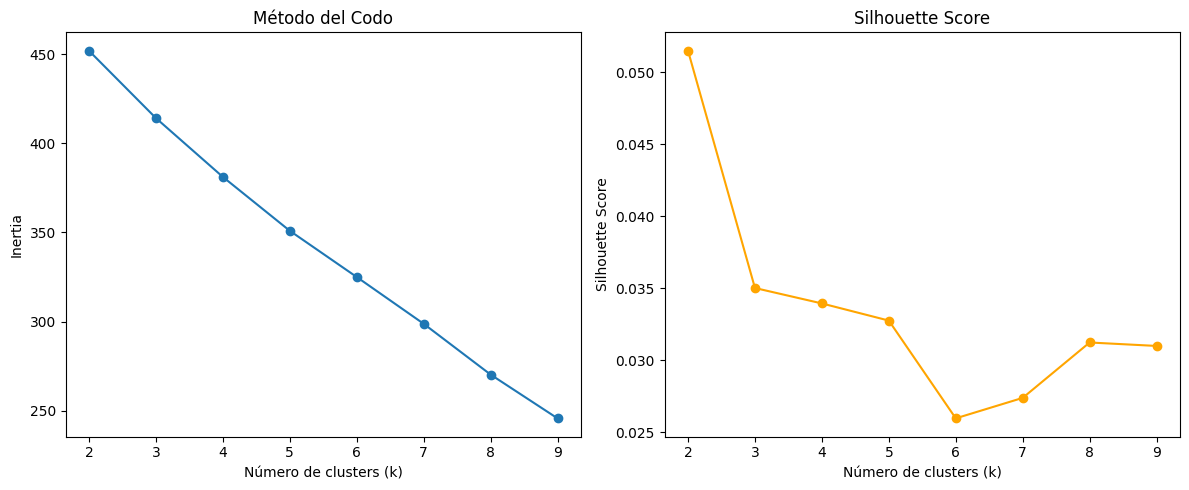

Mejor k por Silhouette Score: 2 (score=0.052)
Mejor k por método del codo: 3 (inertia=414.16)
k sugerido combinando ambos métodos: 2


In [4]:
# Cálculo de k óptimo: método del codo, Silhouette Score y promedio
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia = []
sil_scores = []
K = range(2, 10)
for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X)
    inertia.append(kmeans.inertia_)
    sil_scores.append(silhouette_score(X, labels))

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(K, inertia, marker='o')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Inertia')
plt.title('Método del Codo')
plt.subplot(1,2,2)
plt.plot(K, sil_scores, marker='o', color='orange')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score')
plt.tight_layout()
plt.show()

# Selección automática de k por Silhouette Score
def select_k_silhouette(K, sil_scores):
    best_index = np.argmax(sil_scores)
    return K[best_index], sil_scores[best_index]
k_sil, score_sil = select_k_silhouette(list(K), sil_scores)
print(f'Mejor k por Silhouette Score: {k_sil} (score={score_sil:.3f})')

# Selección automática de k por método del codo
def select_k_elbow(K, inertia):
    inertia_diff = np.diff(inertia)
    inertia_diff2 = np.diff(inertia_diff)
    elbow_index = np.argmax(inertia_diff2) + 1  # +1 por el diff
    return K[elbow_index], inertia[elbow_index]
k_elbow, inertia_elbow = select_k_elbow(list(K), inertia)
print(f'Mejor k por método del codo: {k_elbow} (inertia={inertia_elbow:.2f})')

# Promedio de ambos métodos
k_auto = int(np.round((k_sil + k_elbow) / 2))
print(f'k sugerido combinando ambos métodos: {k_auto}')

## 5. Clusterización y reducción dimensional: PCA y t-SNE

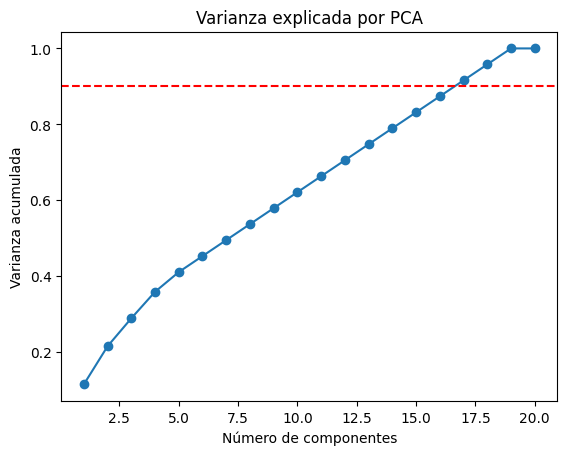

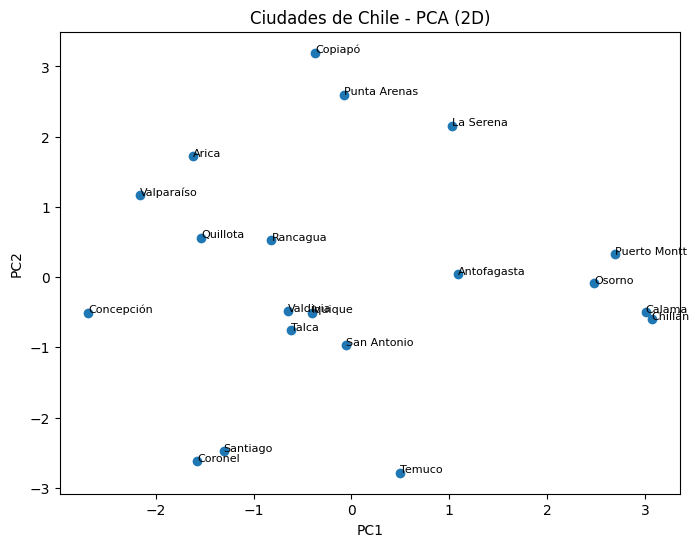

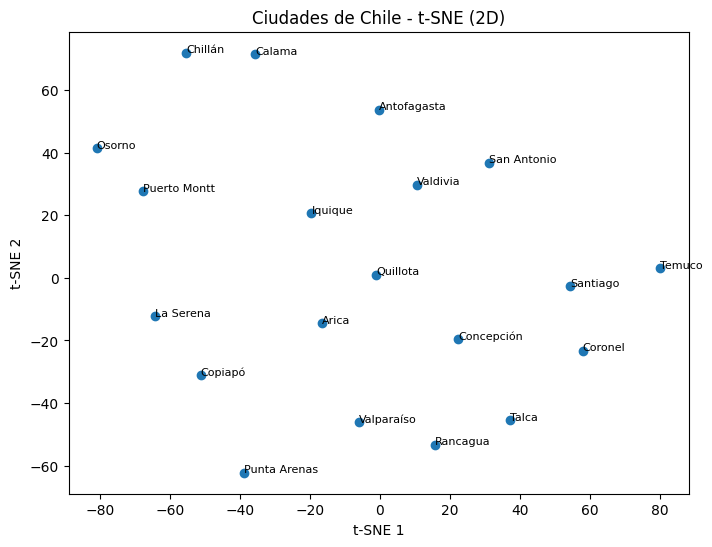

In [5]:
from sklearn.decomposition import PCA
pca = PCA()
X_pca = pca.fit_transform(X)
var_exp = np.cumsum(pca.explained_variance_ratio_)
plt.plot(range(1, len(var_exp)+1), var_exp, marker='o')
plt.axhline(0.9, color='r', linestyle='--')
plt.xlabel('Número de componentes')
plt.ylabel('Varianza acumulada')
plt.title('Varianza explicada por PCA')
plt.show()

pca2 = PCA(n_components=2)
X_pca2 = pca2.fit_transform(X)
plt.figure(figsize=(8,6))
plt.scatter(X_pca2[:,0], X_pca2[:,1])
for i, ciudad in enumerate(df_clean['Ciudad']):
    plt.text(X_pca2[i,0], X_pca2[i,1], ciudad, fontsize=8)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Ciudades de Chile - PCA (2D)')
plt.show()

from sklearn.manifold import TSNE
tsne = TSNE(n_components=2, random_state=42, perplexity=8)
X_tsne = tsne.fit_transform(X)
plt.figure(figsize=(8,6))
plt.scatter(X_tsne[:,0], X_tsne[:,1])
for i, ciudad in enumerate(df_clean['Ciudad']):
    plt.text(X_tsne[i,0], X_tsne[i,1], ciudad, fontsize=8)
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.title('Ciudades de Chile - t-SNE (2D)')
plt.show()

## 6. Clusterización: Jerárquico, K-Means y DBSCAN

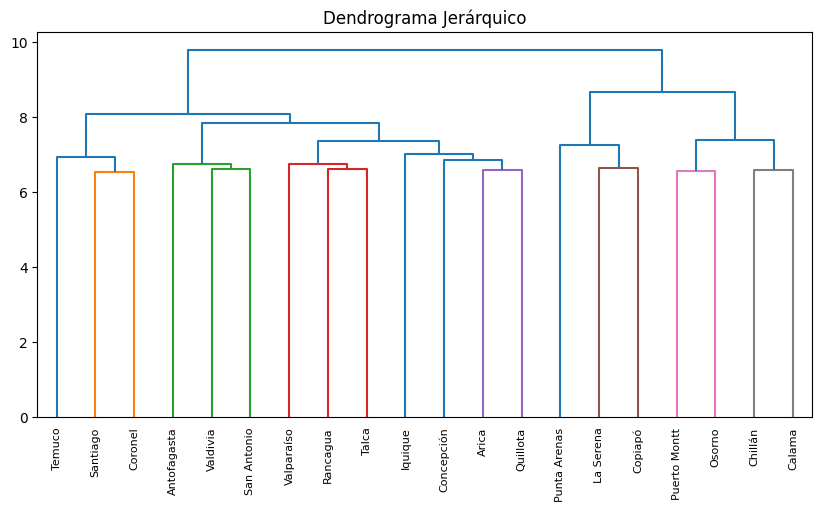

c:\Users\adria\miniconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\adria\miniconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\adria\miniconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\adria\miniconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Wi

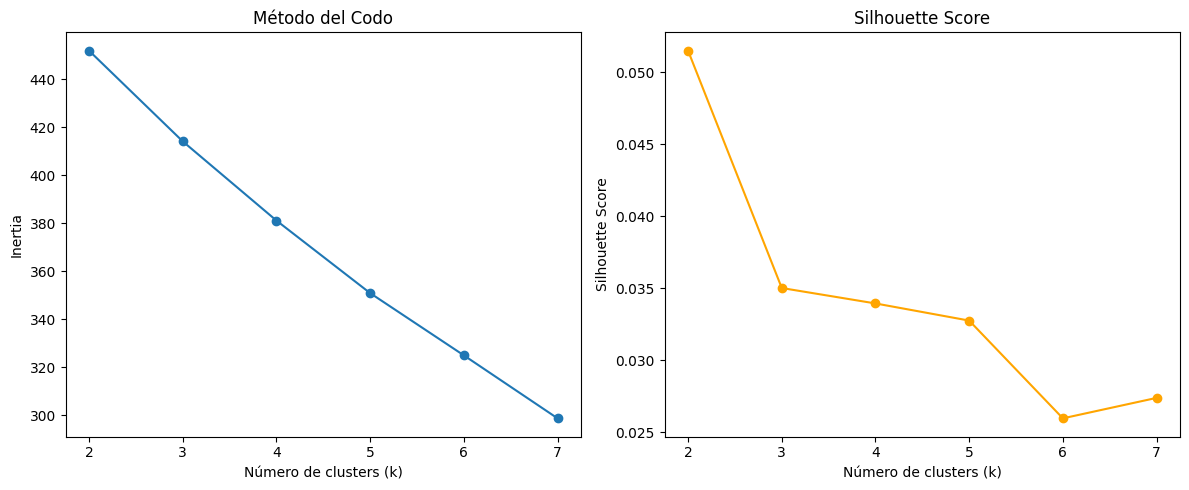

Cantidad óptima de clusters: 2


c:\Users\adria\miniconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [6]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans, DBSCAN
from sklearn.metrics import silhouette_score

linked = linkage(X, method='ward')
plt.figure(figsize=(10,5))
dendrogram(linked, labels=df_clean['Ciudad'].values, leaf_rotation=90, leaf_font_size=8)
plt.title('Dendrograma Jerárquico')
plt.show()

# Agrupamiento jerárquico
agglo = AgglomerativeClustering(n_clusters=4)
labels_agglo = agglo.fit_predict(X)
df_clean['cluster_agglo'] = labels_agglo

# K-Means
inertia = []
sil_scores = []
K = range(2, 8)
for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X)
    inertia.append(kmeans.inertia_)
    sil_scores.append(silhouette_score(X, labels))
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(K, inertia, marker='o')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Inertia')
plt.title('Método del Codo')
plt.subplot(1,2,2)
plt.plot(K, sil_scores, marker='o', color='orange')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score')
plt.tight_layout()
plt.show()
optimal_k = K[np.argmax(sil_scores)]
print(f'Cantidad óptima de clusters: {optimal_k}')
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
labels_kmeans = kmeans.fit_predict(X)
df_clean['cluster_kmeans'] = labels_kmeans

# DBSCAN
dbscan = DBSCAN(eps=1.2, min_samples=2)
labels_dbscan = dbscan.fit_predict(X)
df_clean['cluster_dbscan'] = labels_dbscan

## 7. Visualización de clusters en espacio reducido (PCA y t-SNE)

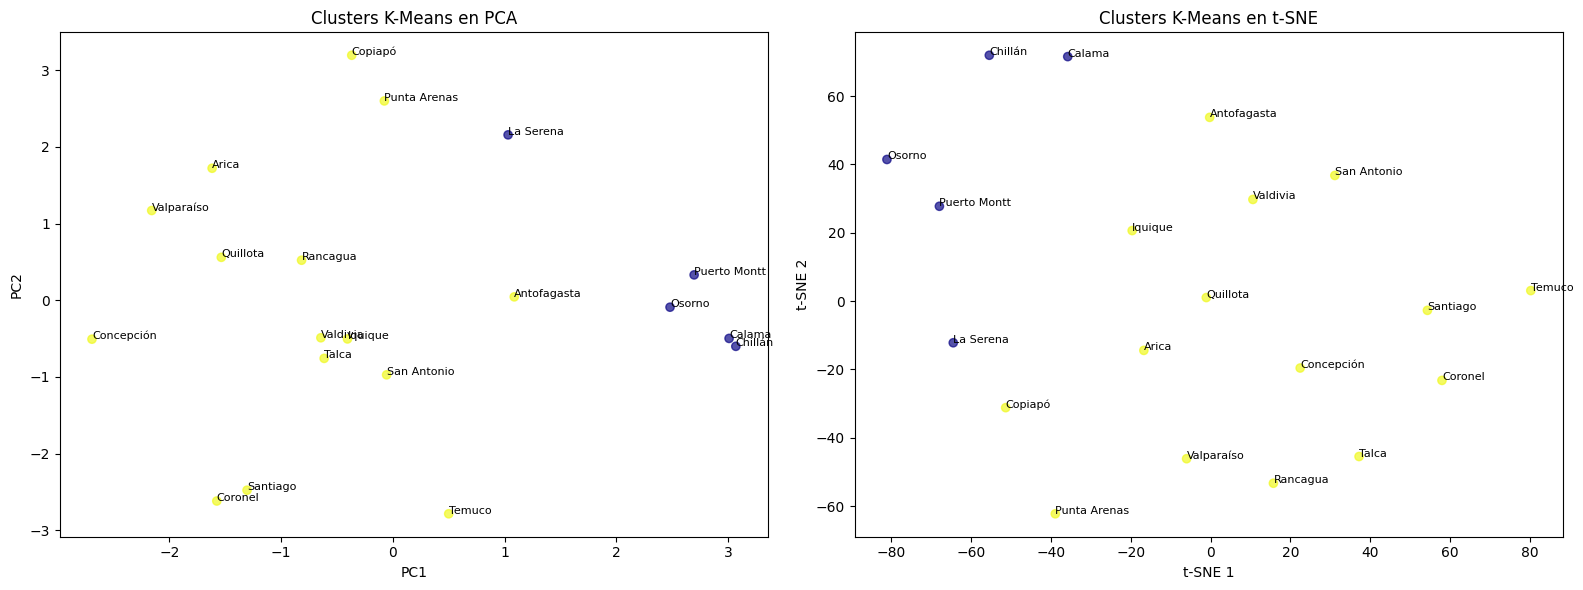

In [7]:
plt.figure(figsize=(16,6))
plt.subplot(1,2,1)
plt.scatter(X_pca2[:,0], X_pca2[:,1], c=df_clean['cluster_kmeans'], cmap='plasma', alpha=0.7)
for i, ciudad in enumerate(df_clean['Ciudad']):
    plt.text(X_pca2[i,0], X_pca2[i,1], ciudad, fontsize=8)
plt.title('Clusters K-Means en PCA')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.subplot(1,2,2)
plt.scatter(X_tsne[:,0], X_tsne[:,1], c=df_clean['cluster_kmeans'], cmap='plasma', alpha=0.7)
for i, ciudad in enumerate(df_clean['Ciudad']):
    plt.text(X_tsne[i,0], X_tsne[i,1], ciudad, fontsize=8)
plt.title('Clusters K-Means en t-SNE')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.tight_layout()
plt.show()

## 8. Visualización y análisis de resultados
### Diferencias entre PCA y t-SNE
- PCA conserva la varianza global y es útil para identificar patrones lineales.
- t-SNE preserva relaciones locales y puede mostrar agrupaciones más claras en datos complejos.

### Interpretación de agrupaciones
- Las ciudades con características similares tienden a agruparse.
- Los clusters pueden relacionarse con aspectos socioeconómicos (ingreso, desempleo) o geográficos.

### Aplicabilidad
- PCA es recomendable para análisis exploratorio y reducción lineal.
- t-SNE es útil para visualización y detección de grupos en datos no lineales.
- La clusterización permite segmentar ciudades para estudios urbanos, políticas públicas o marketing territorial.

In [8]:
# Ejemplo: Identificar ciudades prioritarias para inversión en seguridad pública
# Seleccionamos el cluster con mayor índice de delincuencia y menor ingreso promedio
cluster_stats = df_clean.groupby('cluster_kmeans').agg({'Indice_Delincuencia':'mean','Ingreso_Promedio':'mean'})
print('Estadísticas por cluster:')
display(cluster_stats)

# Identificamos el cluster prioritario (mayor delincuencia, menor ingreso)
prioritario = cluster_stats.sort_values(['Indice_Delincuencia','Ingreso_Promedio'], ascending=[False,True]).index[0]
print(f'Cluster prioritario para inversión en seguridad pública: {prioritario}')

ciudades_prioritarias = df_clean[df_clean['cluster_kmeans']==prioritario]['Ciudad']
print('Ciudades recomendadas para intervención focalizada:')
display(ciudades_prioritarias)

Estadísticas por cluster:


,Indice_Delincuencia,Ingreso_Promedio
cluster_kmeans,,
0,70.109092,792571.537942
1,35.694268,629200.169253


Cluster prioritario para inversión en seguridad pública: 0
Ciudades recomendadas para intervención focalizada:


3        La Serena
10    Puerto Montt
13         Chillán
14          Calama
15          Osorno
Name: Ciudad, dtype: object

## 9. Recomendaciones prácticas
A partir del análisis realizado, se pueden extraer las siguientes recomendaciones y conclusiones:

- Las variables socioeconómicas analizadas permiten diferenciar y segmentar las ciudades de Chile en grupos con características similares.
- La regresión lineal múltiple ayuda a identificar el impacto relativo de cada variable sobre el ingreso promedio, útil para políticas públicas.
- Los métodos de clusterización y reducción dimensional (PCA, t-SNE, K-Means, Jerárquico, DBSCAN) permiten visualizar y entender la estructura de los datos.
- La segmentación obtenida puede ser utilizada para diseñar estrategias focalizadas en desarrollo urbano, seguridad, migración y empleo.

### Ejemplo de aplicación: Segmentación para políticas públicas
Supongamos que queremos identificar ciudades prioritarias para inversión en seguridad pública. Podemos seleccionar los clusters con mayor índice de delincuencia y menor ingreso promedio, y recomendar intervenciones focalizadas en esas ciudades.

A continuación, se muestra cómo identificar estos grupos y listar las ciudades correspondientes.